### 1. Import Dependencies

In [47]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
dependency_location = os.getenv("DEPENDENCY_LOCATION")
feature_engineered_location = os.getenv("FEATURE_ENGINEERED_LOCATION")
data_processed_location = os.getenv("DATA_PROCESSED_LOCATION")
models_location = os.getenv("MODELS_LOCATION")

In [48]:
import joblib
import warnings 
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedKFold, cross_validate
)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
warnings.filterwarnings('ignore')

### 1. Load the Data

In [49]:
X_train = pd.read_csv(os.path.join(data_processed_location, "X_train.csv"))
X_test  = pd.read_csv(os.path.join(data_processed_location, "X_test.csv"))
y_train = pd.read_csv(os.path.join(data_processed_location, "y_train.csv")).squeeze()
y_test  = pd.read_csv(os.path.join(data_processed_location, "y_test.csv")).squeeze()

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (8276, 30) | Test: (1409, 30)
Churn rate train: 0.5 | test: 0.265


### 2. Define Multi Models

In [50]:
models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(),
    "RandomForest": RandomForestClassifier()
}

### 3. Configure K-folds

In [51]:
cv = StratifiedKFold(
    n_splits=6,
    random_state=42,
    shuffle=True
)

### 4. Model Training

In [52]:
trained_models = {}

for model_name, model in models.items():
    print(f"\nCross Validation on {model_name}")
    cv_results = cross_validate(
        model,
        X_train, y_train,
        cv=cv, scoring='f1',
        return_estimator=True,
        return_train_score=False
    )
    
    test_scores = cv_results['test_score']
    print(test_scores)

    best_index = np.argmax(test_scores)
    estimator = cv_results['estimator'][best_index]
    trained_models[model_name] = estimator
    



Cross Validation on KNN
[0.83169614 0.8372093  0.836173   0.83432343 0.85006519 0.83858004]

Cross Validation on Logistic Regression
[0.83120567 0.84104046 0.82437276 0.82480173 0.83533569 0.81910275]

Cross Validation on RandomForest
[0.83798883 0.87420043 0.84674598 0.85874912 0.84487535 0.84709261]


In [53]:
trained_models

{'KNN': KNeighborsClassifier(),
 'Logistic Regression': LogisticRegression(),
 'RandomForest': RandomForestClassifier()}

In [54]:
y_hat_tests = {}
for model_name, model in trained_models.items():
    y_hat_test = model.predict(X_test)
    y_hat_tests[model_name] = y_hat_test

y_hat_tests

{'KNN': array([1, 0, 0, ..., 0, 0, 1], shape=(1409,)),
 'Logistic Regression': array([1, 0, 0, ..., 0, 0, 1], shape=(1409,)),
 'RandomForest': array([1, 0, 0, ..., 0, 0, 0], shape=(1409,))}

In [55]:
results = []

for model_name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index('Model')
print(results_df.round(4))

                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Model                                                              
KNN                    0.7189     0.4803  0.7534    0.5866   0.7948
Logistic Regression    0.7928     0.5890  0.7185    0.6473   0.8551
RandomForest           0.7715     0.5630  0.6113    0.5861   0.8280


### 5. Plotting

In [56]:
cm1 = confusion_matrix(y_test, y_hat_tests['KNN'])
cm2 = confusion_matrix(y_test, y_hat_tests['Logistic Regression'])
cm3 = confusion_matrix(y_test, y_hat_tests['RandomForest'])

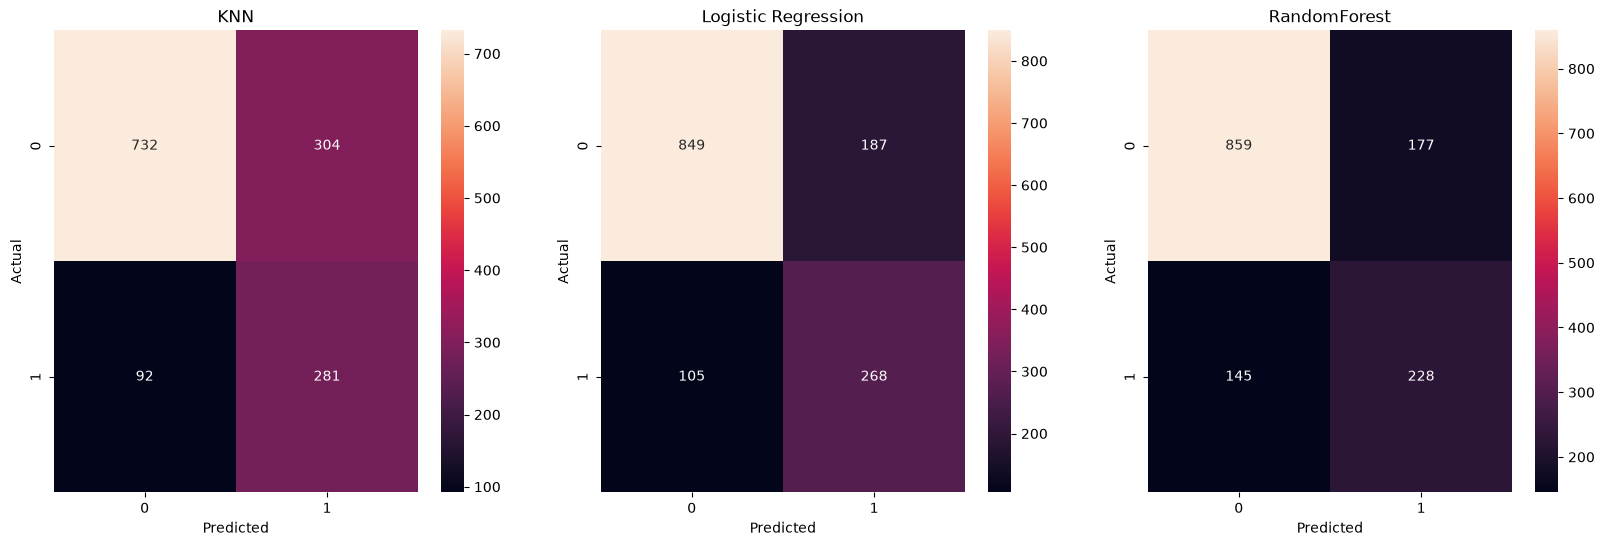

In [57]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (20, 6))

sns.heatmap(cm1, annot=True, fmt='d', ax=ax1)
ax1.set_title('KNN')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

sns.heatmap(cm2, annot=True, fmt='d', ax=ax2)
ax2.set_title('Logistic Regression')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

sns.heatmap(cm3, annot=True, fmt='d', ax=ax3)
ax3.set_title('RandomForest')
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')

plt.show()